# Mini-projet — Apprentissage supervisé avec Scikit-learn
## Prédiction du prix et du segment de prix des voitures d'occasion (Avito.ma)

**Module :** Technologies IA — ENSA Fès — ILIA2  
**Binôme :** *(EL MGHARI Othmane  — El-Abbadi Mohammed )*  
**Jeu de données :** `avito_car_dataset_ALL.csv` (annonces de voitures d'occasion au Maroc)

---

### Démarche
Ce notebook applique le **workflow complet** vu dans les exercices 1 et 2 du TP, sur un même jeu de données :

| Partie | Rappel du TP | Application ici |
|---|---|---|
| **A. Régression** | Exercice 1 (tarif Uber) : `LinearRegression` puis `RandomForestRegressor`, métriques MAE / RMSE / R², nuage réel vs prédit | Prédire le **prix** (MAD) d'une annonce |
| **B. Classification** | Exercice 2 (Titanic) : `LogisticRegression` vs `RandomForestClassifier`, accuracy, `classification_report`, matrice de confusion | Prédire si la voiture est **chère** (prix > médiane) ou **abordable** |

Les 7 étapes de chaque exercice sont suivies dans le même ordre : *chargement → nettoyage → séparation → entraînement → évaluation → amélioration → visualisation*. Nous y ajoutons ce qui manque pour une **comparaison rigoureuse** : modèle de référence (*baseline*), validation croisée, réglage d'hyperparamètres, analyse des erreurs et importance des variables.

> **Plan** : 1. Chargement et exploration — 2. Nettoyage et préparation — 3. Séparation et pré-traitement — 4. Régression — 5. Classification — 6. Synthèse comparative — 7. Conclusion critique

In [1]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.ensemble import (RandomForestRegressor, RandomForestClassifier,
                              HistGradientBoostingRegressor, HistGradientBoostingClassifier)
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, median_absolute_error,
                             accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             classification_report, confusion_matrix, RocCurveDisplay)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
RANDOM_STATE = 42

---
# 1. Chargement et exploration du jeu de données

Les annonces ont été collectées sur Avito.ma. La cible de la partie A est la colonne **`Prix`** (en dirhams).

> ⚠️ Le fichier n'est **pas encodé en UTF-8** (la lecture par défaut lève une `UnicodeDecodeError` à cause des accents). On le lit donc avec `encoding='latin-1'`.

In [2]:
DATA_PATH = "avito_car_dataset_ALL.csv"
df_raw = pd.read_csv(DATA_PATH, encoding="latin-1")

print("Dimensions :", df_raw.shape)
df_raw.head()

Dimensions : (24776, 32)


,Unnamed: 0,Lien,Ville,Secteur,Marque,Modèle,Année-Modèle,Kilométrage,Type de carburant,Puissance fiscale,Boite de vitesses,Nombre de portes,Origine,Première main,État,Jantes aluminium,Airbags,Climatisation,Système de navigation/GPS,Toit ouvrant,Sièges cuir,Radar de recul,Caméra de recul,Vitres électriques,ABS,ESP,Régulateur de vitesse,Limiteur de vitesse,CD/MP3/Bluetooth,Ordinateur de bord,Verrouillage centralisé à distance,Prix
0,0,https://www.avito.ma/fr/massira_2/voitures/FIA...,Temara,Massira 2,Fiat,Punto,2007,200 000 - 249 999,Diesel,5,Manuelle,5.0,WW au Maroc,Non,Très bon,False,False,True,False,False,False,False,False,False,True,False,False,False,True,False,False,60000
1,1,https://www.avito.ma/fr/temara/voitures/Dacia_...,Temara,NaN,Dacia,Dokker Van,2013,400 000 - 449 999,Diesel,6,Manuelle,3.0,WW au Maroc,Non,Excellent,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,70000
2,2,https://www.avito.ma/fr/casablanca/voitures/Da...,Casablanca,NaN,Dacia,Dokker,2014,160 000 - 169 999,Diesel,6,Manuelle,5.0,WW au Maroc,NaN,Très bon,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,90000
3,3,https://www.avito.ma/fr/casablanca/voitures/to...,Casablanca,NaN,Volkswagen,Touareg,2005,0 - 4 999,Diesel,10,Automatique,5.0,WW au Maroc,Oui,Excellent,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,90000
4,4,https://www.avito.ma/fr/dakhla/voitures/Toyota...,Dakhla,NaN,Toyota,Prado,2007,200 000 - 249 999,Diesel,12,Manuelle,5.0,WW au Maroc,Non,Excellent,False,True,False,False,False,False,False,False,False,True,False,False,False,True,False,False,97000


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 24776 entries, 0 to 24775
Data columns (total 32 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Unnamed: 0                          24776 non-null  int64  
 1   Lien                                24776 non-null  str    
 2   Ville                               24776 non-null  str    
 3   Secteur                             10810 non-null  str    
 4   Marque                              24776 non-null  str    
 5   Modèle                              24776 non-null  str    
 6   Année-Modèle                        24776 non-null  int64  
 7   Kilométrage                         24776 non-null  str    
 8   Type de carburant                   24776 non-null  str    
 9   Puissance fiscale                   24776 non-null  int64  
 10  Boite de vitesses                   24776 non-null  str    
 11  Nombre de portes                    20396 non-null  

In [4]:
# Valeurs manquantes
manq = df_raw.isnull().sum()
manq = manq[manq > 0].to_frame("nb_manquants")
manq["pourcentage"] = (manq["nb_manquants"] / len(df_raw) * 100).round(1)
manq

,nb_manquants,pourcentage
Secteur,13966,56.4
Nombre de portes,4380,17.7
Origine,5287,21.3
Première main,6209,25.1
État,6678,27.0


In [5]:
# Statistiques descriptives des variables numériques
df_raw[["Année-Modèle", "Puissance fiscale", "Nombre de portes", "Prix"]].describe(percentiles=[.01, .25, .5, .75, .95, .99, .999]).round(0)

,Année-Modèle,Puissance fiscale,Nombre de portes,Prix
count,24776.0,24776.0,20396.0,24776.0
mean,2012.0,7.0,5.0,216959.0
std,5.0,2.0,0.0,6749569.0
min,1990.0,5.0,3.0,60000.0
1%,1995.0,5.0,3.0,60000.0
25%,2008.0,6.0,5.0,75000.0
50%,2013.0,7.0,5.0,100000.0
75%,2016.0,8.0,5.0,140000.0
95%,2019.0,11.0,5.0,273500.0
99%,2021.0,12.0,5.0,550000.0


In [6]:
# Autres constats importants sur la qualité des données
print("Lignes dupliquées (hors index)  :", df_raw.drop(columns="Unnamed: 0").duplicated().sum(),
      "sur", len(df_raw), f"({df_raw.drop(columns='Unnamed: 0').duplicated().mean():.0%})")
print("Annonces distinctes (colonne Lien) :", df_raw["Lien"].nunique())

cst = [c for c in df_raw.columns if df_raw[c].nunique() == 1]
print("\nColonnes constantes (1 seule valeur) :", cst)

print("\nBoîte de vitesses :", df_raw["Boite de vitesses"].value_counts().to_dict())
print("Modalités Kilométrage :", df_raw["Kilométrage"].nunique(), "tranches, ex. :", df_raw["Kilométrage"].iloc[0])

Lignes dupliquées (hors index)  : 16546 sur 24776 (67%)
Annonces distinctes (colonne Lien) : 8230

Colonnes constantes (1 seule valeur) : ['Jantes aluminium', 'Système de navigation/GPS', 'Toit ouvrant', 'Sièges cuir', 'Radar de recul', 'Caméra de recul', 'Vitres électriques', 'Régulateur de vitesse', 'Limiteur de vitesse', 'Ordinateur de bord', 'Verrouillage centralisé à distance']

Boîte de vitesses : {'Manuelle': 17452, 'Automatique': 4418, '--': 2906}
Modalités Kilométrage : 36 tranches, ex. : 200 000 - 249 999


### Constats de l'exploration
1. **Beaucoup de doublons** : environ deux tiers des lignes sont des copies exactes d'une même annonce (même `Lien`). Si on les garde, une même voiture se retrouvera dans le *train* **et** dans le *test* → les scores seraient artificiellement gonflés (**fuite de données**).
2. **Colonnes inutiles** : `Unnamed: 0` (index), `Lien` (identifiant), et plusieurs colonnes d'équipements **constantes** (toujours `False`) qui n'apportent aucune information.
3. **Valeurs manquantes** : `Secteur` (56 %), `État`, `Première main`, `Origine`, `Nombre de portes`, et un faux manquant codé `'--'` dans `Boite de vitesses`.
4. **`Kilométrage` est une tranche textuelle** (`"200 000 - 249 999"`), à convertir en nombre.
5. **Valeurs aberrantes dans `Prix`** : maximum à plus de 600 millions de dirhams alors que la médiane est autour de 100 000 → erreurs de saisie évidentes.

---
# 2. Nettoyage et préparation
Comme dans le TP : suppression des valeurs inutiles, retrait des valeurs aberrantes, création de variables dérivées.

### 2.1 Suppression des doublons

In [7]:
n0 = len(df_raw)
df = df_raw.drop(columns="Unnamed: 0").drop_duplicates().reset_index(drop=True)
print(f"{n0} lignes -> {len(df)} lignes ({n0 - len(df)} doublons supprimés)")
print("Doublons de Lien restants :", df["Lien"].duplicated().sum())

24776 lignes -> 8230 lignes (16546 doublons supprimés)
Doublons de Lien restants : 0


### 2.2 Suppression des colonnes inutiles
- `Lien` : identifiant, aucune valeur prédictive.
- `Secteur` : 56 % de valeurs manquantes et ~400 modalités (quartiers) → trop creux ; la `Ville` capte déjà l'essentiel de l'information géographique.
- Colonnes constantes : aucune variance, donc aucune information.

In [8]:
constantes = [c for c in df.columns if df[c].nunique() == 1]
print("Colonnes constantes supprimées :", constantes)
df = df.drop(columns=["Lien", "Secteur"] + constantes)

# Noms de colonnes simplifiés (sans accents ni espaces) pour faciliter le code
df = df.rename(columns={
    "Ville": "ville", "Marque": "marque", "Modèle": "modele", "Année-Modèle": "annee",
    "Kilométrage": "km_tranche", "Type de carburant": "carburant", "Puissance fiscale": "puissance_fiscale",
    "Boite de vitesses": "boite", "Nombre de portes": "portes", "Origine": "origine",
    "Première main": "premiere_main", "État": "etat", "Airbags": "airbags", "Climatisation": "clim",
    "ABS": "abs_", "ESP": "esp", "CD/MP3/Bluetooth": "audio", "Prix": "prix"})
print("Colonnes restantes :", list(df.columns))

Colonnes constantes supprimées : ['Jantes aluminium', 'Système de navigation/GPS', 'Toit ouvrant', 'Sièges cuir', 'Radar de recul', 'Caméra de recul', 'Vitres électriques', 'Régulateur de vitesse', 'Limiteur de vitesse', 'Ordinateur de bord', 'Verrouillage centralisé à distance']
Colonnes restantes : ['ville', 'marque', 'modele', 'annee', 'km_tranche', 'carburant', 'puissance_fiscale', 'boite', 'portes', 'origine', 'premiere_main', 'etat', 'airbags', 'clim', 'abs_', 'esp', 'audio', 'prix']


### 2.3 Valeurs manquantes déguisées
`'--'` dans `boite` signifie « non renseigné » : on le remplace par `NaN`. L'imputation proprement dite sera faite **plus tard, dans un pipeline**, uniquement à partir du jeu d'entraînement (le TP la fait avant la séparation, ce qui laisse fuiter des informations du test vers le train).

In [9]:
df["boite"] = df["boite"].replace("--", np.nan)
df.isnull().mean().mul(100).round(1)[lambda s: s > 0].to_frame("% manquants")

,% manquants
boite,11.7
portes,17.7
origine,21.3
premiere_main,25.1
etat,26.9


### 2.4 Conversion du kilométrage (tranche → valeur numérique)
On remplace chaque tranche par son **milieu** (ex. `"200 000 - 249 999"` → 225 000). Cela introduit une erreur de quantification maximale d'une demi-tranche, acceptable ici.

In [10]:
def milieu_tranche(s):
    bas, haut = [int(x) for x in s.replace(" ", "").split("-")]
    return (bas + haut) / 2

df["km"] = df["km_tranche"].apply(milieu_tranche)
df[["km_tranche", "km"]].drop_duplicates().sort_values("km").head(6)

,km_tranche,km
3,0 - 4 999,2499.5
39,5 000 - 9 999,7499.5
8,10 000 - 14 999,12499.5
93,15 000 - 19 999,17499.5
23,20 000 - 24 999,22499.5
61,25 000 - 29 999,27499.5


### 2.5 Valeurs aberrantes sur le prix
On regarde la distribution des prix avant de décider d'un seuil.

In [11]:
print(df["prix"].quantile([.5, .9, .95, .99, .995, .999]).round(0).to_string())
print("\nAnnonces à plus de 1 000 000 MAD :")
df.loc[df["prix"] > 1_000_000, ["marque", "modele", "annee", "km", "prix"]].sort_values("prix").tail(12)

0.500     100000.0
0.900     205000.0
0.950     275000.0
0.990     550000.0
0.995     848550.0
0.999    6231300.0

Annonces à plus de 1 000 000 MAD :


,marque,modele,annee,km,prix
3595,Citroen,Berlingo,2008,224999.5,5500000
3760,Peugeot,406,2003,104999.5,6000000
8055,Chevrolet,El Camino,2008,2499.5,6000000
7163,Renault,Kangoo,2000,72499.5,6300000
298,Dacia,Dokker,2013,224999.5,7800000
4129,Peugeot,301,2014,12499.5,8300000
5811,Renault,Laguna,2009,174999.5,8300000
7147,Citroen,C3,2015,154999.5,10000000
8044,Citroen,Jumpy,2010,164999.5,10000000
8085,Suzuki,Vitara,2012,174999.5,14000000


Au-delà de **1 000 000 MAD**, on trouve des Dacia Logan à 5 millions, une Renault 12 à 612 millions, etc. : ce sont des prix saisis avec des zéros en trop ou des valeurs fantaisistes, **pas** des prix de marché. Les voitures réellement chères de la base (Range Rover, BMW Série 4 neuve, Classe CLS…) se situent à 800–900 k MAD, donc **sous** le seuil. On retient un seuil de **1 000 000 MAD** (≈ 0,4 % des annonces, soit 30 annonces).

30 annonces supprimées (0.36%) -> 8200 lignes restantes


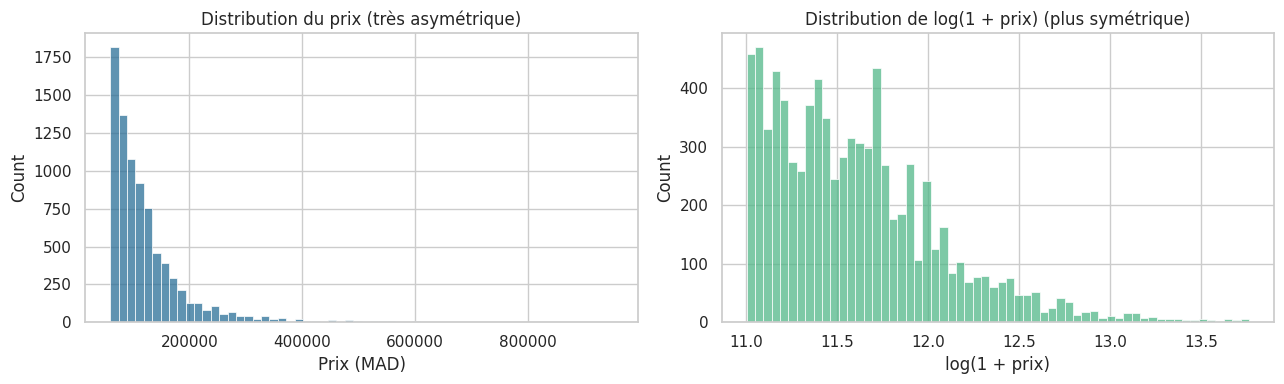

Part des annonces à exactement 60 000 MAD (valeur minimale) : 3.5%


In [12]:
SEUIL_PRIX = 1_000_000
avant = len(df)
df = df[df["prix"] <= SEUIL_PRIX].reset_index(drop=True)
print(f"{avant - len(df)} annonces supprimées ({(avant - len(df)) / avant:.2%}) -> {len(df)} lignes restantes")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["prix"], bins=60, ax=ax[0], color="#2a6f97")
ax[0].set_title("Distribution du prix (très asymétrique)")
ax[0].set_xlabel("Prix (MAD)")
sns.histplot(np.log1p(df["prix"]), bins=60, ax=ax[1], color="#52b788")
ax[1].set_title("Distribution de log(1 + prix) (plus symétrique)")
ax[1].set_xlabel("log(1 + prix)")
plt.tight_layout(); plt.show()

print(f"Part des annonces à exactement 60 000 MAD (valeur minimale) : {(df['prix'] == 60000).mean():.1%}")

**Observations**
- Le prix est fortement **asymétrique à droite** : on utilisera une transformation **logarithmique de la cible** pour la régression (les erreurs deviennent relatives plutôt qu'absolues).
- ~3,5 % des annonces sont **exactement à 60 000 MAD**, valeur qui est aussi le minimum : la collecte semble avoir un **plancher de prix** (données *censurées à gauche*). Nous les conservons mais nous en tiendrons compte dans la discussion des limites.

### 2.6 Variables dérivées
Comme `hour` et `day_of_week` dans l'exercice Uber, on construit des variables plus informatives que les colonnes brutes :
- `age` : âge du véhicule (les annonces datent de 2022, année maximale du jeu de données) ;
- `km_par_an` : kilométrage moyen annuel (usage intensif ou non) ;
- `nb_equipements` : nombre d'équipements de confort/sécurité.

In [13]:
ANNEE_REF = int(df["annee"].max())          # 2022 : année de collecte
EQUIP = ["airbags", "clim", "abs_", "esp", "audio"]

df["age"] = (ANNEE_REF - df["annee"]).clip(lower=0)
df["km_par_an"] = df["km"] / (df["age"] + 1)
df[EQUIP] = df[EQUIP].astype(int)
df["nb_equipements"] = df[EQUIP].sum(axis=1)

df[["annee", "age", "km", "km_par_an", "nb_equipements", "prix"]].describe().round(1)

,annee,age,km,km_par_an,nb_equipements,prix
count,8200.0,8200.0,8200.0,8200.0,8200.0,8200.0
mean,2011.8,10.2,133049.8,13046.1,2.6,124463.4
std,5.5,5.5,89142.4,7710.9,2.1,83098.1
min,1990.0,0.0,2499.5,78.1,0.0,60000.0
25%,2008.0,6.0,62499.5,8749.8,0.0,75000.0
50%,2013.0,9.0,124999.5,13500.0,3.0,100000.0
75%,2016.0,14.0,194999.5,17499.9,5.0,140000.0
max,2022.0,32.0,474999.5,141666.5,5.0,950000.0


### 2.7 Exploration visuelle

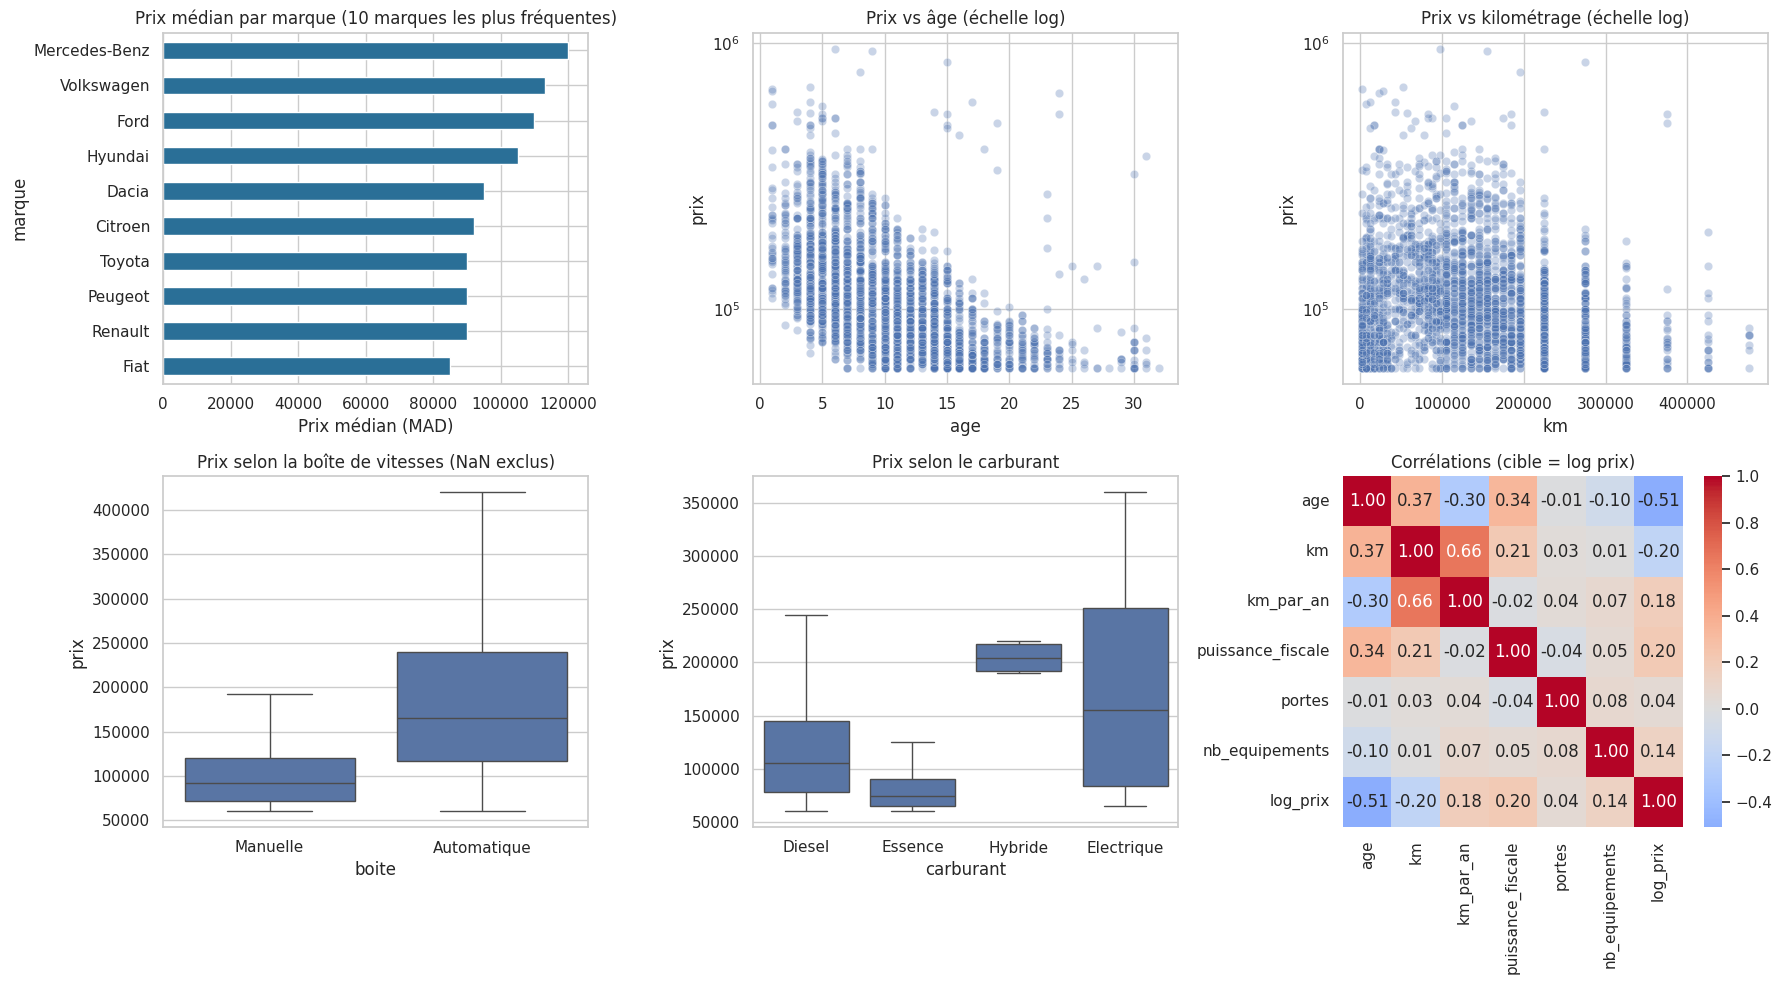

In [14]:
fig, ax = plt.subplots(2, 3, figsize=(18, 10))

top_marques = df["marque"].value_counts().head(10).index
med = df[df["marque"].isin(top_marques)].groupby("marque")["prix"].median().sort_values()
med.plot.barh(ax=ax[0, 0], color="#2a6f97")
ax[0, 0].set_title("Prix médian par marque (10 marques les plus fréquentes)"); ax[0, 0].set_xlabel("Prix médian (MAD)")

sns.scatterplot(data=df.sample(3000, random_state=0), x="age", y="prix", alpha=.3, ax=ax[0, 1])
ax[0, 1].set_yscale("log"); ax[0, 1].set_title("Prix vs âge (échelle log)")

sns.scatterplot(data=df.sample(3000, random_state=0), x="km", y="prix", alpha=.3, ax=ax[0, 2])
ax[0, 2].set_yscale("log"); ax[0, 2].set_title("Prix vs kilométrage (échelle log)")

sns.boxplot(data=df, x="boite", y="prix", ax=ax[1, 0], showfliers=False)
ax[1, 0].set_title("Prix selon la boîte de vitesses (NaN exclus)")

sns.boxplot(data=df, x="carburant", y="prix", ax=ax[1, 1], showfliers=False)
ax[1, 1].set_title("Prix selon le carburant")

num_corr = df[["prix", "age", "km", "km_par_an", "puissance_fiscale", "portes", "nb_equipements"]].copy()
num_corr["log_prix"] = np.log1p(num_corr.pop("prix"))
sns.heatmap(num_corr.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[1, 2])
ax[1, 2].set_title("Corrélations (cible = log prix)")
plt.tight_layout(); plt.show()

**Lecture rapide** : le prix baisse avec l'âge (corrélation ≈ −0,51 avec le log du prix) et, plus faiblement, avec le kilométrage (≈ −0,20) ; il augmente avec la puissance fiscale (≈ +0,20). Les automatiques (médiane ≈ 165 000 MAD) sont nettement plus chères que les manuelles (≈ 92 000 MAD), les diesel (≈ 105 000) plus chères que les essence (≈ 74 000), et des marques comme Land Rover, Audi ou BMW se situent au-dessus des généralistes (Renault, Peugeot, Fiat, Kia). Les hybrides et électriques sont trop rares (6 annonces chacun) pour conclure. **L'âge est le facteur le plus corrélé au prix.**

---
# 3. Séparation des données et pré-traitement

On sépare **80 % entraînement / 20 % test** avec `random_state=42` (comme dans le TP). Toutes les transformations (imputation, standardisation, encodage) sont encapsulées dans un **`ColumnTransformer` + `Pipeline`** : elles sont **apprises uniquement sur le train**, puis appliquées au test. C'est la façon correcte d'éviter la fuite de données.

| Type | Variables | Traitement |
|---|---|---|
| Numériques | `age`, `puissance_fiscale`, `portes`, `km`, `km_par_an`, `nb_equipements`, `airbags`, `clim`, `abs_`, `esp`, `audio` | imputation par la médiane (+ indicateur de valeur manquante) puis standardisation |
| Catégorielles | `ville`, `marque`, `modele`, `carburant`, `boite`, `origine`, `premiere_main`, `etat` | valeur manquante → modalité « Inconnu », puis *one-hot* ; les modalités rares (< 20 annonces) sont regroupées |

*(La variable `annee` n'est pas utilisée en plus de `age`, qui contient la même information.)*

In [15]:
NUM = ["age", "puissance_fiscale", "portes", "km", "km_par_an", "nb_equipements"] + EQUIP
CAT = ["ville", "marque", "modele", "carburant", "boite", "origine", "premiere_main", "etat"]

# Les colonnes catégorielles sont mises en type "object" pour que l'imputeur gère proprement les NaN
df[CAT] = df[CAT].astype(object).where(df[CAT].notna(), np.nan)

X = df[NUM + CAT]
y = df["prix"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train :", X_train.shape, "| Test :", X_test.shape)

preprocessor = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                      ("sc", StandardScaler())]), NUM),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Inconnu")),
                      ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20,
                                            sparse_output=False))]), CAT),
])

Xt = clone(preprocessor).fit_transform(X_train)
print("Nombre de variables après pré-traitement :", Xt.shape[1])

Train : (6560, 19) | Test : (1640, 19)
Nombre de variables après pré-traitement : 172


---
# 4. Partie A — Régression : prédire le prix

*(Suit l'exercice 1 : régression linéaire → Random Forest → métriques MAE/RMSE/R² → nuage réel vs prédit.)*

### 4.1 Entraînement des modèles et évaluation sur le jeu de test (Étapes 4 et 5 du TP)

Modèles comparés :
- **Baseline** (`DummyRegressor`, prédit toujours la médiane) : le minimum à battre.
- **Régression linéaire** sur le prix brut (comme dans le TP).
- **Régression linéaire** avec cible `log(1 + prix)` : teste l'intérêt de la transformation.
- **Ridge** (régression linéaire régularisée) avec cible log.
- **Random Forest** (cible log) — Étape 6 « Amélioration » du TP.
- **Gradient Boosting** (`HistGradientBoostingRegressor`, cible log) — alternative moderne aux forêts.

Pour la cible log, `TransformedTargetRegressor` entraîne sur `log(1+prix)` mais **renvoie des prédictions en dirhams**, de sorte que toutes les métriques restent comparables.

In [16]:
def make_reg(model, log=True):
    """Pipeline complet : pré-traitement + modèle (avec ou sans transformation log de la cible)."""
    pipe = Pipeline([("prep", clone(preprocessor)), ("model", model)])
    if log:
        return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)
    return pipe

reg_models = {
    "Baseline (médiane)":            make_reg(DummyRegressor(strategy="median"), log=False),
    "Régression linéaire (prix brut)": make_reg(LinearRegression(), log=False),
    "Régression linéaire (log prix)":  make_reg(LinearRegression()),
    "Ridge (log prix)":              make_reg(Ridge(alpha=10)),
    "Random Forest":                 make_reg(RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)),
    "Gradient Boosting":             make_reg(HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
}

def scores_reg(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R²": r2_score(y_true, y_pred),
            "MedAE": median_absolute_error(y_true, y_pred)}

lignes, pred_reg = [], {}
for nom, est in reg_models.items():
    est.fit(X_train, y_train)
    pred_reg[nom] = est.predict(X_test)
    s = scores_reg(y_test, pred_reg[nom])
    s["R² train"] = r2_score(y_train, est.predict(X_train))
    lignes.append({"Modèle": nom, **s})

res_reg = pd.DataFrame(lignes).set_index("Modèle")
res_reg.round(3)

,MAE,RMSE,R²,MedAE,R² train
Modèle,,,,,
Baseline (médiane),45394.782,78413.164,-0.094,28000.000,-0.085
Régression linéaire (prix brut),26949.742,51267.006,0.532,17125.064,0.448
Régression linéaire (log prix),19744.690,46871.033,0.609,9665.931,0.492
Ridge (log prix),19959.204,47076.674,0.606,10345.667,0.486
Random Forest,17264.216,42295.037,0.682,8214.674,0.848
Gradient Boosting,16919.287,41468.165,0.694,8564.616,0.646


`MAE` = erreur absolue moyenne (en MAD), `RMSE` pénalise davantage les grosses erreurs, `MedAE` = erreur médiane (robuste aux annonces extrêmes). La colonne **`R² train`** sert à détecter le **sur-apprentissage** : un écart important entre `R² train` et `R²` test signale un modèle qui mémorise.

### 4.2 Comparaison rigoureuse par validation croisée (5 plis)
Un seul découpage train/test peut être favorable ou défavorable par hasard. On répète donc l'évaluation sur **5 plis** du jeu d'entraînement (mêmes plis pour tous les modèles) et on regarde la **moyenne ± écart-type**.

In [17]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring_reg = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R²": "r2"}

cv_rows = []
for nom, est in reg_models.items():
    cv = cross_validate(est, X_train, y_train, cv=kf, scoring=scoring_reg, n_jobs=1)
    cv_rows.append({"Modèle": nom,
                    "MAE (cv)":  -cv["test_MAE"].mean(),  "± MAE":  cv["test_MAE"].std(),
                    "RMSE (cv)": -cv["test_RMSE"].mean(), "± RMSE": cv["test_RMSE"].std(),
                    "R² (cv)":   cv["test_R²"].mean(),    "± R²":   cv["test_R²"].std()})
cv_reg = pd.DataFrame(cv_rows).set_index("Modèle")
cv_reg.round(3)

,MAE (cv),± MAE,RMSE (cv),± RMSE,R² (cv),± R²
Modèle,,,,,,
Baseline (médiane),47391.725,2756.871,88241.117,7416.118,-0.086,0.005
Régression linéaire (prix brut),29504.174,1438.087,64946.460,5956.284,0.412,0.021
Régression linéaire (log prix),22369.052,1539.510,61159.171,6240.758,0.479,0.029
Ridge (log prix),22611.196,1630.072,61438.626,6311.185,0.475,0.028
Random Forest,20097.174,1333.083,57565.934,5276.022,0.538,0.018
Gradient Boosting,19444.568,1393.373,56312.652,5303.617,0.558,0.016


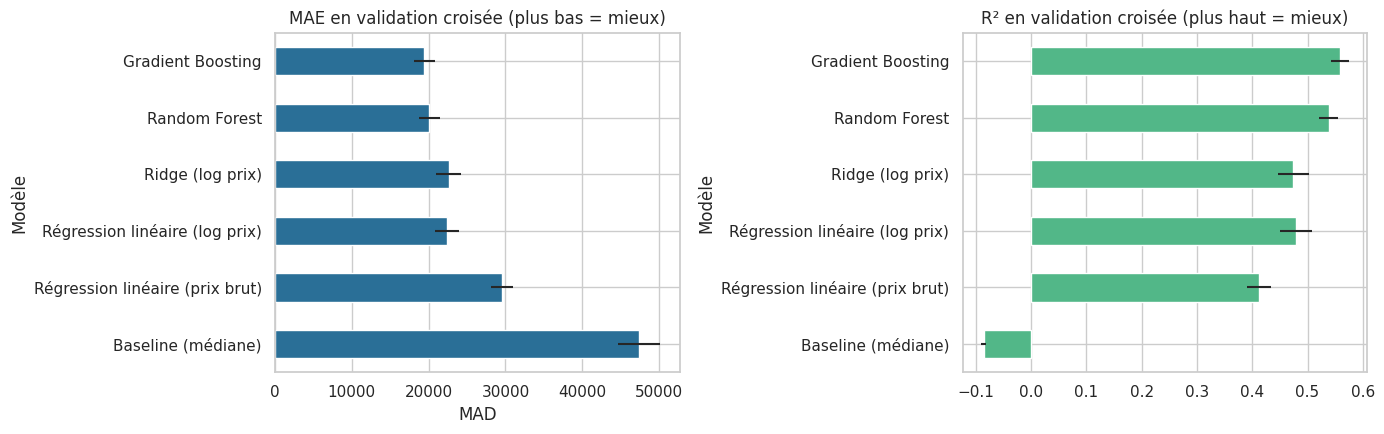

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
cv_reg["MAE (cv)"].plot.barh(xerr=cv_reg["± MAE"], ax=ax[0], color="#2a6f97")
ax[0].set_title("MAE en validation croisée (plus bas = mieux)"); ax[0].set_xlabel("MAD")
cv_reg["R² (cv)"].plot.barh(xerr=cv_reg["± R²"], ax=ax[1], color="#52b788")
ax[1].set_title("R² en validation croisée (plus haut = mieux)")
plt.tight_layout(); plt.show()

### 4.3 Amélioration : réglage des hyperparamètres
On optimise les deux meilleurs modèles d'arbres par `RandomizedSearchCV` (3 plis, critère MAE) — uniquement sur le **jeu d'entraînement**. Le jeu de test reste intact pour l'évaluation finale.

In [19]:
# Random Forest
rf_search = RandomizedSearchCV(
    make_reg(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)),
    param_distributions={
        "regressor__model__n_estimators": [150, 250],
        "regressor__model__max_depth": [None, 20, 30],
        "regressor__model__min_samples_leaf": [1, 2, 4],
        "regressor__model__max_features": [0.3, 0.5, 1.0],
    },
    n_iter=8, cv=3, scoring="neg_mean_absolute_error", random_state=RANDOM_STATE, n_jobs=1)
rf_search.fit(X_train, y_train)
print("Random Forest — meilleurs paramètres :", {k.split("__")[-1]: v for k, v in rf_search.best_params_.items()})
print(f"  MAE (cv, 3 plis) : {-rf_search.best_score_:,.0f} MAD")

# Gradient Boosting
hgb_search = RandomizedSearchCV(
    make_reg(HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
    param_distributions={
        "regressor__model__learning_rate": [0.03, 0.05, 0.1],
        "regressor__model__max_iter": [200, 400, 600],
        "regressor__model__max_leaf_nodes": [15, 31, 63],
        "regressor__model__min_samples_leaf": [10, 20, 40],
        "regressor__model__l2_regularization": [0, 0.1, 1.0],
    },
    n_iter=10, cv=3, scoring="neg_mean_absolute_error", random_state=RANDOM_STATE, n_jobs=1)
hgb_search.fit(X_train, y_train)
print("\nGradient Boosting — meilleurs paramètres :", {k.split("__")[-1]: v for k, v in hgb_search.best_params_.items()})
print(f"  MAE (cv, 3 plis) : {-hgb_search.best_score_:,.0f} MAD")

Random Forest — meilleurs paramètres : {'n_estimators': 150, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': None}
  MAE (cv, 3 plis) : 20,808 MAD



Gradient Boosting — meilleurs paramètres : {'min_samples_leaf': 10, 'max_leaf_nodes': 63, 'max_iter': 600, 'learning_rate': 0.03, 'l2_regularization': 0}
  MAE (cv, 3 plis) : 19,751 MAD


In [20]:
# Évaluation sur le test des modèles réglés
reg_tuned = {"Random Forest (réglé)": rf_search.best_estimator_,
             "Gradient Boosting (réglé)": hgb_search.best_estimator_}
rows = []
for nom, est in reg_tuned.items():
    pred_reg[nom] = est.predict(X_test)
    rows.append({"Modèle": nom, **scores_reg(y_test, pred_reg[nom]), "R² train": r2_score(y_train, est.predict(X_train))})
res_reg = pd.concat([res_reg, pd.DataFrame(rows).set_index("Modèle")])
res_reg.round(3)

,MAE,RMSE,R²,MedAE,R² train
Modèle,,,,,
Baseline (médiane),45394.782,78413.164,-0.094,28000.000,-0.085
Régression linéaire (prix brut),26949.742,51267.006,0.532,17125.064,0.448
Régression linéaire (log prix),19744.690,46871.033,0.609,9665.931,0.492
Ridge (log prix),19959.204,47076.674,0.606,10345.667,0.486
Random Forest,17264.216,42295.037,0.682,8214.674,0.848
Gradient Boosting,16919.287,41468.165,0.694,8564.616,0.646
Random Forest (réglé),17345.974,42424.111,0.680,8261.424,0.846
Gradient Boosting (réglé),16553.340,41107.011,0.699,8081.597,0.794


### 4.4 Choix du modèle final de régression
Le modèle final est choisi **sur la validation croisée** (jamais sur le test, pour ne pas « tricher » en sélectionnant le modèle qui a le mieux deviné le test). On compare les deux modèles réglés à leur score de validation croisée, puis on évalue **une seule fois** le gagnant sur le test.

In [21]:
cv_tuned = {"Random Forest (réglé)": -rf_search.best_score_, "Gradient Boosting (réglé)": -hgb_search.best_score_}
nom_reg_final = min(cv_tuned, key=cv_tuned.get)
reg_final = reg_tuned[nom_reg_final]
print("Modèle final de régression :", nom_reg_final)
print({k: round(v, 3) for k, v in scores_reg(y_test, pred_reg[nom_reg_final]).items()})

Modèle final de régression : Gradient Boosting (réglé)
{'MAE': 16553.34, 'RMSE': np.float64(41107.011), 'R²': 0.699, 'MedAE': 8081.597}


### 4.5 Visualisation des résultats (Étape 7 du TP)

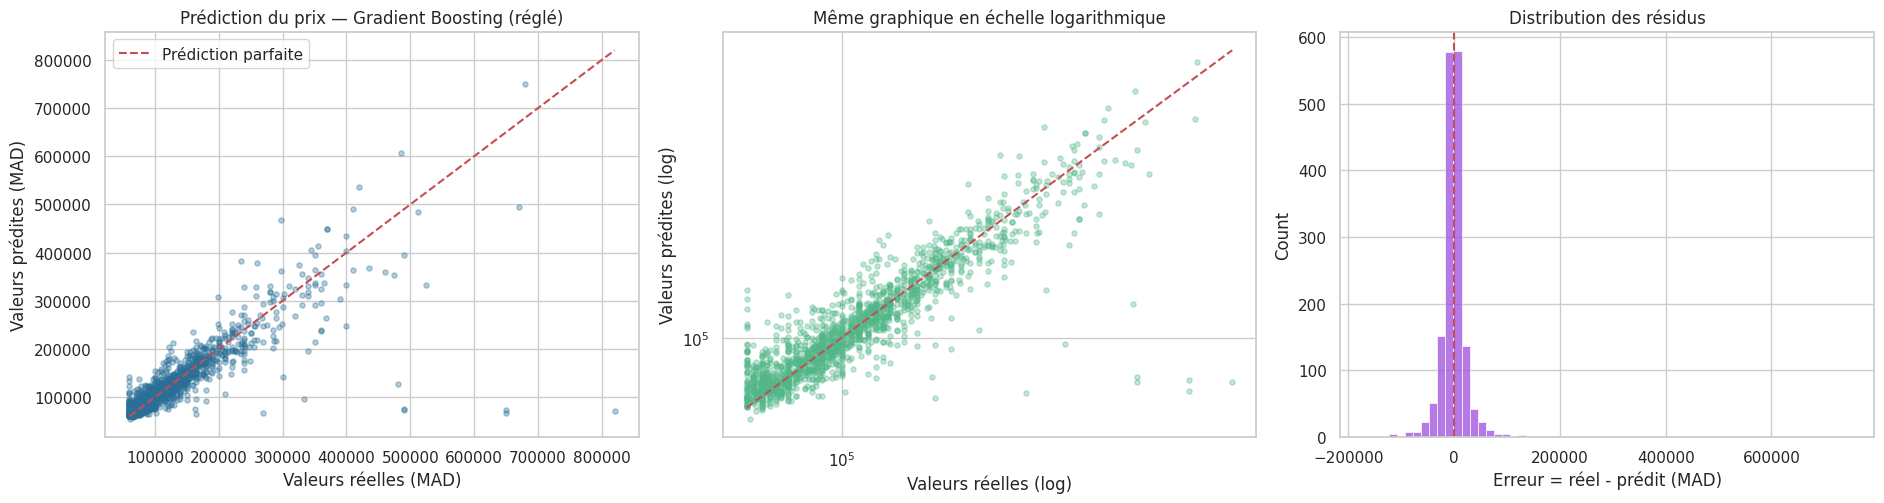

In [22]:
y_pred_final = pred_reg[nom_reg_final]
residus = y_test - y_pred_final

fig, ax = plt.subplots(1, 3, figsize=(19, 5.2))

# Réel vs prédit (comme dans le TP)
ax[0].scatter(y_test, y_pred_final, alpha=.35, s=14, color="#2a6f97")
lim = [y_test.min(), y_test.max()]
ax[0].plot(lim, lim, "r--", label="Prédiction parfaite")
ax[0].set_xlabel("Valeurs réelles (MAD)"); ax[0].set_ylabel("Valeurs prédites (MAD)")
ax[0].set_title(f"Prédiction du prix — {nom_reg_final}"); ax[0].legend()

# Même graphique en échelle log : lit mieux les voitures bon marché
ax[1].scatter(y_test, y_pred_final, alpha=.35, s=14, color="#52b788")
ax[1].plot(lim, lim, "r--")
ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_xlabel("Valeurs réelles (log)"); ax[1].set_ylabel("Valeurs prédites (log)")
ax[1].set_title("Même graphique en échelle logarithmique")

# Distribution des résidus
sns.histplot(residus, bins=60, ax=ax[2], color="#9d4edd")
ax[2].axvline(0, color="r", ls="--")
ax[2].set_xlabel("Erreur = réel - prédit (MAD)"); ax[2].set_title("Distribution des résidus")
plt.tight_layout(); plt.show()

In [23]:
# Où le modèle se trompe-t-il le plus ? Erreur selon la tranche de prix réel
tr = pd.DataFrame({"prix": y_test, "pred": y_pred_final})
tr["tranche"] = pd.cut(tr["prix"], [0, 70_000, 100_000, 150_000, 250_000, 1_000_000],
                       labels=["≤70k", "70-100k", "100-150k", "150-250k", ">250k"])
tr["err_abs"] = (tr["prix"] - tr["pred"]).abs()
tr["err_rel_%"] = tr["err_abs"] / tr["prix"] * 100
tr.groupby("tranche", observed=True).agg(n=("prix", "size"), MAE=("err_abs", "mean"),
                                         erreur_relative_mediane_pct=("err_rel_%", "median")).round(1)

,n,MAE,erreur_relative_mediane_pct
tranche,,,
≤70k,301,9367.7,8.7
70-100k,548,8650.9,7.0
100-150k,450,12882.4,7.2
150-250k,250,22457.3,8.7
>250k,91,89842.7,16.3


### 4.6 Interprétation : quelles variables comptent le plus ?
On utilise l'**importance par permutation** : on mélange aléatoirement une variable du jeu de test et on mesure de combien l'erreur augmente. Plus l'augmentation est grande, plus le modèle dépend de cette variable. (Calculée sur les variables d'origine, donc directement lisible.)

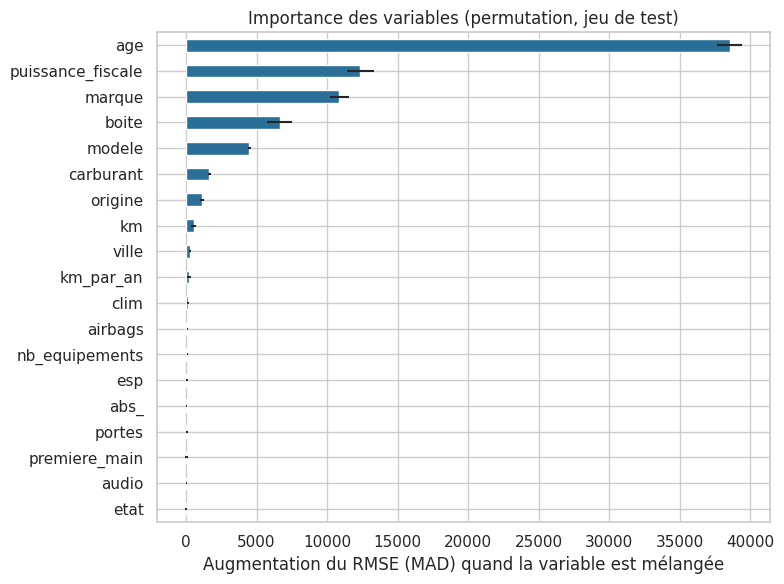

,Δ RMSE (MAD)
age,38544.0
puissance_fiscale,12370.0
marque,10880.0
boite,6638.0
modele,4495.0
carburant,1658.0


In [24]:
perm = permutation_importance(reg_final, X_test, y_test, n_repeats=5, random_state=RANDOM_STATE,
                              scoring="neg_root_mean_squared_error", n_jobs=1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
plt.figure(figsize=(8, 6))
imp.plot.barh(xerr=pd.Series(perm.importances_std, index=X_test.columns)[imp.index], color="#2a6f97")
plt.xlabel("Augmentation du RMSE (MAD) quand la variable est mélangée")
plt.title("Importance des variables (permutation, jeu de test)")
plt.tight_layout(); plt.show()
imp.sort_values(ascending=False).head(6).round(0).to_frame("Δ RMSE (MAD)")

---
# 5. Partie B — Classification : voiture « chère » ou « abordable » ?

*(Suit l'exercice 2 : régression logistique vs Random Forest → accuracy → `classification_report` → matrice de confusion.)*

### 5.1 Définition de la cible
Le jeu de données ne contient pas de classe naturelle ; on en construit une : **`1` = voiture chère** (prix **strictement supérieur à la médiane des prix du train**), **`0` = abordable**. Prendre la médiane donne deux classes **équilibrées**, ce qui rend l'accuracy interprétable. Le seuil est calculé sur le **train uniquement**, et la variable `prix` est naturellement **exclue des features** (sinon la tâche serait triviale).

On réutilise **exactement le même découpage** train/test que pour la régression.

In [25]:
seuil = y_train.median()
yc_train = (y_train > seuil).astype(int)
yc_test = (y_test > seuil).astype(int)
print(f"Seuil (médiane du train) : {seuil:,.0f} MAD")
print("Répartition train :", yc_train.value_counts(normalize=True).round(3).to_dict())
print("Répartition test  :", yc_test.value_counts(normalize=True).round(3).to_dict())

Seuil (médiane du train) : 100,000 MAD
Répartition train : {0: 0.505, 1: 0.495}
Répartition test  : {0: 0.518, 1: 0.482}


### 5.2 Entraînement et évaluation (Étapes 5 et 6 du TP)
Modèles : **baseline** (classe majoritaire), **régression logistique** et **Random Forest** (ceux du TP), plus **Gradient Boosting**.

In [26]:
def make_clf(model):
    return Pipeline([("prep", clone(preprocessor)), ("model", model)])

clf_models = {
    "Baseline (classe majoritaire)": make_clf(DummyClassifier(strategy="most_frequent")),
    "Régression logistique":        make_clf(LogisticRegression(max_iter=1000)),
    "Random Forest":                make_clf(RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)),
    "Gradient Boosting":            make_clf(HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
}

def scores_clf(y_true, y_pred, y_proba):
    return {"Accuracy": accuracy_score(y_true, y_pred), "Précision": precision_score(y_true, y_pred),
            "Rappel": recall_score(y_true, y_pred), "F1": f1_score(y_true, y_pred),
            "AUC": roc_auc_score(y_true, y_proba)}

rows, pred_clf, proba_clf = [], {}, {}
for nom, est in clf_models.items():
    est.fit(X_train, yc_train)
    pred_clf[nom] = est.predict(X_test)
    proba_clf[nom] = est.predict_proba(X_test)[:, 1]
    rows.append({"Modèle": nom, **scores_clf(yc_test, pred_clf[nom], proba_clf[nom]),
                 "Accuracy train": accuracy_score(yc_train, est.predict(X_train))})
res_clf = pd.DataFrame(rows).set_index("Modèle")
res_clf.round(3)

,Accuracy,Précision,Rappel,F1,AUC,Accuracy train
Modèle,,,,,,
Baseline (classe majoritaire),0.518,0.000,0.000,0.000,0.500,0.505
Régression logistique,0.908,0.897,0.914,0.905,0.961,0.906
Random Forest,0.893,0.892,0.885,0.888,0.956,1.000
Gradient Boosting,0.914,0.919,0.901,0.910,0.970,0.946


### 5.3 Validation croisée stratifiée (5 plis)

In [27]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring_clf = {"Accuracy": "accuracy", "F1": "f1", "AUC": "roc_auc"}

rows = []
for nom, est in clf_models.items():
    cv = cross_validate(est, X_train, yc_train, cv=skf, scoring=scoring_clf, n_jobs=1)
    rows.append({"Modèle": nom,
                 "Accuracy (cv)": cv["test_Accuracy"].mean(), "± Acc": cv["test_Accuracy"].std(),
                 "F1 (cv)": cv["test_F1"].mean(), "± F1": cv["test_F1"].std(),
                 "AUC (cv)": cv["test_AUC"].mean(), "± AUC": cv["test_AUC"].std()})
cv_clf = pd.DataFrame(rows).set_index("Modèle")
cv_clf.round(3)

,Accuracy (cv),± Acc,F1 (cv),± F1,AUC (cv),± AUC
Modèle,,,,,,
Baseline (classe majoritaire),0.505,0.000,0.000,0.000,0.500,0.000
Régression logistique,0.894,0.008,0.893,0.007,0.952,0.004
Random Forest,0.874,0.008,0.872,0.008,0.946,0.005
Gradient Boosting,0.904,0.006,0.902,0.006,0.961,0.004


### 5.4 Amélioration : réglage des hyperparamètres

In [28]:
# Régression logistique : force de régularisation C
lr_search = RandomizedSearchCV(
    make_clf(LogisticRegression(max_iter=2000)),
    {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
    n_iter=7, cv=3, scoring="roc_auc", random_state=RANDOM_STATE, n_jobs=1).fit(X_train, yc_train)
print("Régression logistique — C optimal :", lr_search.best_params_["model__C"], f"| AUC cv = {lr_search.best_score_:.4f}")

# Random Forest
rfc_search = RandomizedSearchCV(
    make_clf(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
    {"model__n_estimators": [150, 250], "model__max_depth": [None, 15, 25],
     "model__min_samples_leaf": [1, 2, 4], "model__max_features": ["sqrt", 0.3, 0.5]},
    n_iter=8, cv=3, scoring="roc_auc", random_state=RANDOM_STATE, n_jobs=1).fit(X_train, yc_train)
print("Random Forest — meilleurs paramètres :", {k.split("__")[-1]: v for k, v in rfc_search.best_params_.items()},
      f"| AUC cv = {rfc_search.best_score_:.4f}")

# Gradient Boosting
hgbc_search = RandomizedSearchCV(
    make_clf(HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
    {"model__learning_rate": [0.03, 0.05, 0.1], "model__max_iter": [150, 300, 500],
     "model__max_leaf_nodes": [15, 31, 63], "model__min_samples_leaf": [10, 20, 40],
     "model__l2_regularization": [0, 0.1, 1.0]},
    n_iter=10, cv=3, scoring="roc_auc", random_state=RANDOM_STATE, n_jobs=1).fit(X_train, yc_train)
print("Gradient Boosting — meilleurs paramètres :", {k.split("__")[-1]: v for k, v in hgbc_search.best_params_.items()},
      f"| AUC cv = {hgbc_search.best_score_:.4f}")

Régression logistique — C optimal : 3 | AUC cv = 0.9523


Random Forest — meilleurs paramètres : {'n_estimators': 250, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 25} | AUC cv = 0.9548


Gradient Boosting — meilleurs paramètres : {'min_samples_leaf': 20, 'max_leaf_nodes': 31, 'max_iter': 300, 'learning_rate': 0.03, 'l2_regularization': 1.0} | AUC cv = 0.9583


In [29]:
clf_tuned = {"Régression logistique (réglée)": lr_search, "Random Forest (réglé)": rfc_search,
             "Gradient Boosting (réglé)": hgbc_search}
rows = []
for nom, s in clf_tuned.items():
    est = s.best_estimator_
    pred_clf[nom] = est.predict(X_test)
    proba_clf[nom] = est.predict_proba(X_test)[:, 1]
    rows.append({"Modèle": nom, **scores_clf(yc_test, pred_clf[nom], proba_clf[nom]),
                 "Accuracy train": accuracy_score(yc_train, est.predict(X_train))})
res_clf = pd.concat([res_clf, pd.DataFrame(rows).set_index("Modèle")])

# Choix du modèle final sur la validation croisée (et non sur le test)
nom_clf_final = max(clf_tuned, key=lambda k: clf_tuned[k].best_score_)
clf_final = clf_tuned[nom_clf_final].best_estimator_
print("Modèle final de classification (meilleure AUC en validation croisée) :", nom_clf_final)
res_clf.round(3)

Modèle final de classification (meilleure AUC en validation croisée) : Gradient Boosting (réglé)


,Accuracy,Précision,Rappel,F1,AUC,Accuracy train
Modèle,,,,,,
Baseline (classe majoritaire),0.518,0.000,0.000,0.000,0.500,0.505
Régression logistique,0.908,0.897,0.914,0.905,0.961,0.906
Random Forest,0.893,0.892,0.885,0.888,0.956,1.000
Gradient Boosting,0.914,0.919,0.901,0.910,0.970,0.946
Régression logistique (réglée),0.910,0.900,0.915,0.908,0.960,0.908
Random Forest (réglé),0.910,0.911,0.903,0.907,0.966,0.999
Gradient Boosting (réglé),0.918,0.925,0.904,0.914,0.970,0.937


### 5.5 Rapport de classification et matrices de confusion (Étape 7 du TP)

In [30]:
noms_classes = ["Abordable (0)", "Chère (1)"]
for nom in ["Régression logistique (réglée)", "Random Forest (réglé)", "Gradient Boosting (réglé)"]:
    print("=" * 62, f"\n{nom}\n" + "=" * 62)
    print(classification_report(yc_test, pred_clf[nom], target_names=noms_classes, digits=3))

Régression logistique (réglée)
               precision    recall  f1-score   support

Abordable (0)      0.920     0.906     0.913       849
    Chère (1)      0.900     0.915     0.908       791

     accuracy                          0.910      1640
    macro avg      0.910     0.911     0.910      1640
 weighted avg      0.911     0.910     0.910      1640

Random Forest (réglé)
               precision    recall  f1-score   support

Abordable (0)      0.910     0.918     0.914       849
    Chère (1)      0.911     0.903     0.907       791

     accuracy                          0.910      1640
    macro avg      0.910     0.910     0.910      1640
 weighted avg      0.910     0.910     0.910      1640

Gradient Boosting (réglé)
               precision    recall  f1-score   support

Abordable (0)      0.912     0.932     0.922       849
    Chère (1)      0.925     0.904     0.914       791

     accuracy                          0.918      1640
    macro avg      0.919     0.91

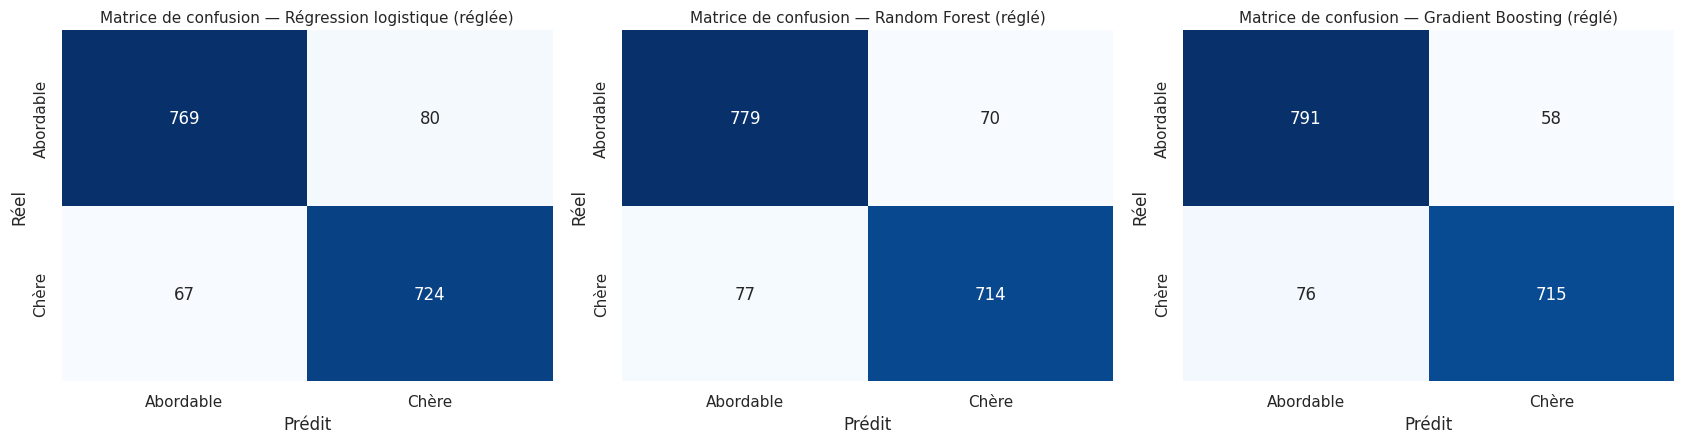

In [31]:
affiches = ["Régression logistique (réglée)", "Random Forest (réglé)", "Gradient Boosting (réglé)"]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for a, nom in zip(ax, affiches):
    cm = confusion_matrix(yc_test, pred_clf[nom])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=a, cbar=False,
                xticklabels=["Abordable", "Chère"], yticklabels=["Abordable", "Chère"])
    a.set_title(f"Matrice de confusion — {nom}", fontsize=11); a.set_xlabel("Prédit"); a.set_ylabel("Réel")
plt.tight_layout(); plt.show()

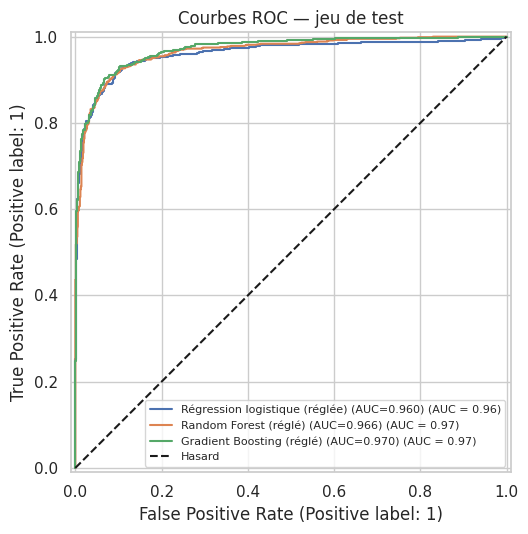

In [32]:
# Courbes ROC
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for nom in affiches:
    RocCurveDisplay.from_predictions(yc_test, proba_clf[nom], name=f"{nom} (AUC={roc_auc_score(yc_test, proba_clf[nom]):.3f})", ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Hasard")
ax.set_title("Courbes ROC — jeu de test"); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

### 5.6 Interprétation
**(a) Les erreurs de classification sont-elles aléatoires ?** On regarde le taux d'erreur selon la distance entre le prix réel et le seuil : on s'attend à ce que le modèle se trompe surtout sur les voitures **proches de la médiane**.

,n,taux_erreur
zone,,
< 10 %,329,0.237
10-25 %,446,0.072
25-50 %,524,0.021
50-100 %,175,0.017
> 100 %,166,0.060


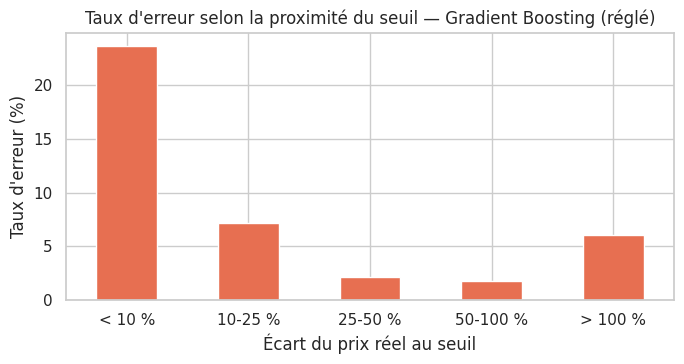

In [33]:
err = pd.DataFrame({"prix": y_test, "ok": (pred_clf[nom_clf_final] == yc_test)})
err["ecart_au_seuil_%"] = (err["prix"] - seuil).abs() / seuil * 100
err["zone"] = pd.cut(err["ecart_au_seuil_%"], [-0.1, 10, 25, 50, 100, np.inf],
                     labels=["< 10 %", "10-25 %", "25-50 %", "50-100 %", "> 100 %"])
taux = err.groupby("zone", observed=True)["ok"].agg(n="size", taux_erreur=lambda s: 1 - s.mean())
display(taux.round(3))
taux["taux_erreur"].mul(100).plot.bar(color="#e76f51", figsize=(7, 3.8), rot=0)
plt.ylabel("Taux d'erreur (%)"); plt.xlabel("Écart du prix réel au seuil")
plt.title(f"Taux d'erreur selon la proximité du seuil — {nom_clf_final}")
plt.tight_layout(); plt.show()

**(b) Quelles variables poussent le modèle linéaire vers « chère » ou « abordable » ?** Coefficients de la régression logistique réglée (les variables numériques sont standardisées, donc comparables entre elles).

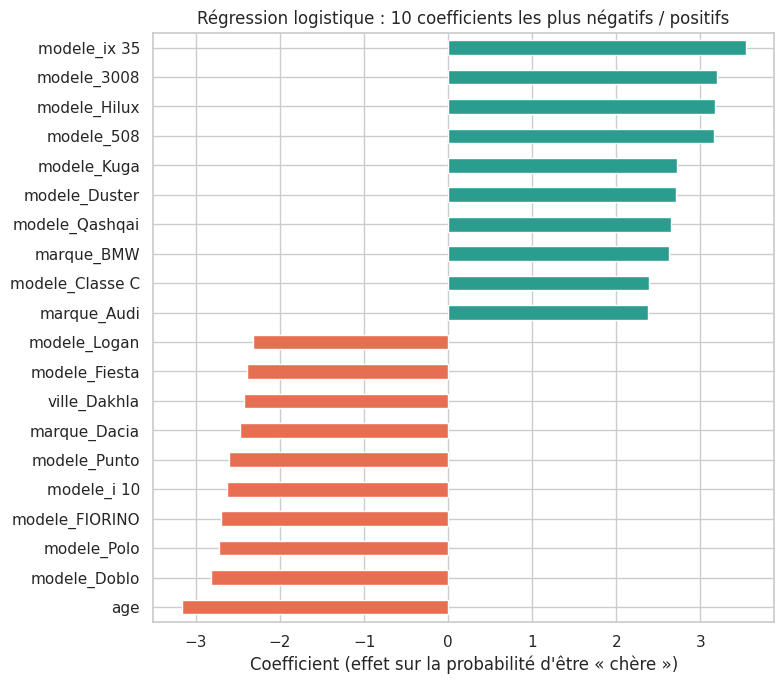

In [34]:
lr_pipe = lr_search.best_estimator_
noms_vars = lr_pipe.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(lr_pipe.named_steps["model"].coef_[0], index=noms_vars).sort_values()
coefs.index = [n.replace("num__", "").replace("cat__", "") for n in coefs.index]

top = pd.concat([coefs.head(10), coefs.tail(10)])
plt.figure(figsize=(8, 7))
top.plot.barh(color=["#e76f51" if v < 0 else "#2a9d8f" for v in top])
plt.title("Régression logistique : 10 coefficients les plus négatifs / positifs")
plt.xlabel("Coefficient (effet sur la probabilité d'être « chère »)")
plt.tight_layout(); plt.show()

---
# 6. Synthèse comparative

In [35]:
print("RÉGRESSION — jeu de test (modèles triés par MAE)")
display(res_reg.sort_values("MAE").round(3))
print("\nRÉGRESSION — validation croisée 5 plis sur le train")
display(cv_reg.sort_values("MAE (cv)").round(3))

RÉGRESSION — jeu de test (modèles triés par MAE)


,MAE,RMSE,R²,MedAE,R² train
Modèle,,,,,
Gradient Boosting (réglé),16553.340,41107.011,0.699,8081.597,0.794
Gradient Boosting,16919.287,41468.165,0.694,8564.616,0.646
Random Forest,17264.216,42295.037,0.682,8214.674,0.848
Random Forest (réglé),17345.974,42424.111,0.680,8261.424,0.846
Régression linéaire (log prix),19744.690,46871.033,0.609,9665.931,0.492
Ridge (log prix),19959.204,47076.674,0.606,10345.667,0.486
Régression linéaire (prix brut),26949.742,51267.006,0.532,17125.064,0.448
Baseline (médiane),45394.782,78413.164,-0.094,28000.000,-0.085



RÉGRESSION — validation croisée 5 plis sur le train


,MAE (cv),± MAE,RMSE (cv),± RMSE,R² (cv),± R²
Modèle,,,,,,
Gradient Boosting,19444.568,1393.373,56312.652,5303.617,0.558,0.016
Random Forest,20097.174,1333.083,57565.934,5276.022,0.538,0.018
Régression linéaire (log prix),22369.052,1539.510,61159.171,6240.758,0.479,0.029
Ridge (log prix),22611.196,1630.072,61438.626,6311.185,0.475,0.028
Régression linéaire (prix brut),29504.174,1438.087,64946.460,5956.284,0.412,0.021
Baseline (médiane),47391.725,2756.871,88241.117,7416.118,-0.086,0.005


In [36]:
print("CLASSIFICATION — jeu de test (modèles triés par AUC)")
display(res_clf.sort_values("AUC", ascending=False).round(3))
print("\nCLASSIFICATION — validation croisée stratifiée 5 plis sur le train")
display(cv_clf.sort_values("AUC (cv)", ascending=False).round(3))

CLASSIFICATION — jeu de test (modèles triés par AUC)


,Accuracy,Précision,Rappel,F1,AUC,Accuracy train
Modèle,,,,,,
Gradient Boosting (réglé),0.918,0.925,0.904,0.914,0.970,0.937
Gradient Boosting,0.914,0.919,0.901,0.910,0.970,0.946
Random Forest (réglé),0.910,0.911,0.903,0.907,0.966,0.999
Régression logistique,0.908,0.897,0.914,0.905,0.961,0.906
Régression logistique (réglée),0.910,0.900,0.915,0.908,0.960,0.908
Random Forest,0.893,0.892,0.885,0.888,0.956,1.000
Baseline (classe majoritaire),0.518,0.000,0.000,0.000,0.500,0.505



CLASSIFICATION — validation croisée stratifiée 5 plis sur le train


,Accuracy (cv),± Acc,F1 (cv),± F1,AUC (cv),± AUC
Modèle,,,,,,
Gradient Boosting,0.904,0.006,0.902,0.006,0.961,0.004
Régression logistique,0.894,0.008,0.893,0.007,0.952,0.004
Random Forest,0.874,0.008,0.872,0.008,0.946,0.005
Baseline (classe majoritaire),0.505,0.000,0.000,0.000,0.500,0.000


In [37]:
print(f"Modèle final régression      : {nom_reg_final}")
s = scores_reg(y_test, pred_reg[nom_reg_final])
print(f"   MAE = {s['MAE']:,.0f} MAD | RMSE = {s['RMSE']:,.0f} MAD | R² = {s['R²']:.3f} | erreur médiane = {s['MedAE']:,.0f} MAD")
print(f"Modèle final classification  : {nom_clf_final}")
s = scores_clf(yc_test, pred_clf[nom_clf_final], proba_clf[nom_clf_final])
print("   " + " | ".join(f"{k} = {v:.3f}" for k, v in s.items()))

Modèle final régression      : Gradient Boosting (réglé)
   MAE = 16,553 MAD | RMSE = 41,107 MAD | R² = 0.699 | erreur médiane = 8,082 MAD
Modèle final classification  : Gradient Boosting (réglé)
   Accuracy = 0.918 | Précision = 0.925 | Rappel = 0.904 | F1 = 0.914 | AUC = 0.970


---
# 7. Conclusion critique

> Les valeurs chiffrées ci-dessous proviennent de l'exécution avec `random_state=42` ; elles peuvent varier légèrement selon la version de scikit-learn, mais les conclusions restent les mêmes.

## 7.1 Résultats principaux

| Tâche | Modèle | Résultats sur le test | Validation croisée (train) |
|---|---|---|---|
| **Régression** (prix) | Baseline (médiane) | MAE ≈ 45 400 MAD, R² < 0 | MAE ≈ 47 400 |
| | Régression linéaire (prix brut) | MAE ≈ 26 900, R² ≈ 0,53 | MAE ≈ 29 500 |
| | Régression linéaire (log prix) | MAE ≈ 19 700, R² ≈ 0,61 | MAE ≈ 22 400 |
| | Random Forest (réglé) | MAE ≈ 17 300, R² ≈ 0,68 | MAE ≈ 20 100 (avant réglage) |
| | **Gradient Boosting (réglé)** | **MAE ≈ 16 600, RMSE ≈ 41 100, R² ≈ 0,70, erreur médiane ≈ 8 100** | **MAE ≈ 19 400** |
| **Classification** (chère / abordable) | Baseline (classe majoritaire) | accuracy ≈ 0,52 | ≈ 0,51 |
| | Régression logistique (réglée) | accuracy ≈ 0,910, F1 ≈ 0,908, AUC ≈ 0,960 | AUC ≈ 0,952 |
| | Random Forest (réglé) | accuracy ≈ 0,910, F1 ≈ 0,907, AUC ≈ 0,966 | AUC ≈ 0,955 |
| | **Gradient Boosting (réglé)** | **accuracy ≈ 0,918, F1 ≈ 0,914, AUC ≈ 0,970** | **AUC ≈ 0,958** |

## 7.2 Quel modèle retenir, et pourquoi ?

**Nous retenons le Gradient Boosting (`HistGradientBoosting`) pour les deux tâches.**

- **Régression** : les modèles d'arbres battent nettement les modèles linéaires (MAE test ≈ 16 600 contre ≈ 19 700 pour la régression linéaire en log, soit environ −16 %). Les effets sont non linéaires et dépendent des interactions (une même marque ne se déprécie pas de la même façon selon l'âge), ce qu'un modèle linéaire ne capte pas. Le Gradient Boosting est aussi le meilleur en validation croisée (MAE ≈ 19 400 contre ≈ 20 100 pour la Random Forest), **sur-apprend moins** que la forêt (R² train ≈ 0,79 contre ≈ 0,85 ; accuracy train ≈ 0,94 contre ≈ 1,00 en classification) et s'entraîne plus vite.
- **Transformation logarithmique de la cible** : c'est l'amélioration la plus rentable à moindre coût (MAE ≈ 26 900 → ≈ 19 700 et erreur médiane ≈ 17 100 → ≈ 9 700 avec le même modèle linéaire), car le prix est très asymétrique.
- **Classification** : le Gradient Boosting a la meilleure AUC en validation croisée, mais **l'écart avec les autres modèles est faible**. L'avantage en accuracy sur la régression logistique (0,918 contre 0,910) représente une douzaine de voitures sur 1 640, ce qui reste dans la marge d'incertitude (≈ ± 0,7 point). Si l'**interprétabilité** prime (expliquer pourquoi une voiture est jugée chère), la **régression logistique est un choix tout à fait défendable** ; si la performance prime, on prend le Gradient Boosting.
- **Réglage des hyperparamètres** : gain réel mais modeste (≲ 2 %), ce qui suggère que le plafond est surtout fixé par les données et non par le réglage.

## 7.3 Interprétation des résultats

- **Variables déterminantes** : l'**âge** domine très largement (le RMSE augmente d'environ 38 500 MAD quand on le mélange), suivi de la **puissance fiscale**, de la **marque**, de la **boîte de vitesses** et du **modèle**. Cela correspond à l'intuition du marché : l'ancienneté et la catégorie du véhicule font le prix. Attention : ces variables sont corrélées entre elles (marque, modèle, puissance), donc l'importance par permutation **sous-estime** chacune d'elles prise isolément.
- **Erreurs de régression** : l'erreur relative médiane est d'environ 7 à 9 % pour les voitures jusqu'à 250 000 MAD, mais grimpe à ≈ 16 % (MAE ≈ 90 000 MAD) au-delà de 250 000 MAD : peu d'exemples, véhicules très hétérogènes (récents, haut de gamme).
- **Erreurs de classification** : elles ne sont pas aléatoires. Le taux d'erreur est d'environ **24 %** pour les voitures situées à ±10 % du seuil (≈ 100 000 MAD), mais seulement **≈ 2 %** à plus de 25 % d'écart. Le modèle se trompe donc surtout là où la frontière est de toute façon arbitraire (une voiture à 98 000 MAD n'est pas fondamentalement différente d'une à 102 000 MAD).

## 7.4 Limites et points critiques

1. **Le prix est un prix demandé** dans une annonce, pas un prix de vente : la négociation n'est pas observée, et les prix « ronds » sont très fréquents (≈ 2 % des annonces à exactement 100 000 MAD, ce qui est justement notre seuil de classification).
2. **Données censurées** : ≈ 3,5 % des annonces sont à exactement 60 000 MAD (le minimum), ce qui trahit un plancher dans la collecte ; les voitures les moins chères sont donc mal représentées.
3. **Valeurs aberrantes** : le seuil de 1 000 000 MAD a été fixé par jugement (30 annonces retirées). Un autre choix modifierait un peu les métriques, en particulier le RMSE, très sensible aux extrêmes.
4. **Doublons** : deux tiers du fichier étaient des copies d'une même annonce, retirées. Une même voiture republiée sous un autre lien ne peut pas être détectée et pourrait subsister des deux côtés du découpage, ce qui rend les scores légèrement optimistes.
5. **Écart validation croisée / test** : le R² est ≈ 0,56 en validation croisée mais ≈ 0,70 sur le test. Le jeu de test contient simplement moins de prix extrêmes (le RMSE est très sensible à la queue de distribution). **La validation croisée est l'estimation la plus fiable** ; les métriques robustes (MAE, erreur médiane) sont plus stables que le RMSE.
6. **Information manquante** : kilométrage connu seulement par tranches, état / origine / « première main » absents pour 20 à 27 % des annonces, et aucune information sur la version, les accidents ou l'état réel. Une partie de la variance du prix est donc inexplicable avec ces colonnes.
7. **La cible de classification est construite à partir du prix** : elle n'apporte pas d'information nouvelle par rapport à la régression (on pourrait seuiller les prédictions de régression), et ses scores dépendent du seuil choisi. Elle est utile surtout pour comparer rigoureusement les classifieurs.
8. **Réglage limité** (recherche aléatoire de 8 à 10 combinaisons, 3 plis) pour tenir dans un temps de calcul raisonnable ; une recherche plus large pourrait gagner un peu.
9. **Pas de dimension temporelle** : les annonces datent d'une période précise du marché marocain (2022) ; le modèle ne serait pas valable tel quel dans le temps.

## 7.5 Pistes d'amélioration
- Exploiter le **texte du lien / titre de l'annonce** (version, finition) et regrouper marque + modèle en une variable.
- Tester un **encodage par moyenne de cible** pour les variables à nombreuses modalités (`modele`, `ville`).
- Fournir un **intervalle de prédiction** (régression par quantiles) plutôt qu'une valeur unique, plus utile à un acheteur ou un vendeur.
- Entraîner des modèles séparés par **segment** (citadines/utilitaires vs haut de gamme), où les erreurs sont aujourd'hui les plus grandes.
- Comparer les modèles avec des **tests statistiques** sur les plis de validation croisée plutôt que sur un seul score.